# Net-zero pathways and carbon budgets

Decarbonization pathway benchmarks and the cumulative carbon budgets implied by reduction rates.

Run the notebook from top to bottom. Local section numbers are retained within each part.

1. [11f: Net-zero pathway benchmarks](#part-11f)
2. [11g: Net-zero carbon budget: compounding reduction worked examples](#part-11g)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from csaps import csaps
from scipy.optimize import brentq
from quanttoolbox.sustainable_finance.carbon import carbon_budget_compound_reduction as _qtb_cbcr

<a id="part-11f"></a>

## Part 1 — 11f: Net-zero pathway benchmarks

Self-contained illustrations of global/sector emissions scenarios and
normalized decarbonization-pathway benchmarks (IEA scenario data,
NZAOA/CTB/PAB stylized targets), all built from hardcoded IEA-style
data — no external files. Smoothing-spline fits use the `csaps` package
(`csaps(x,y,p,xi)`, with smoothing parameter `p` in $[0,1]$: `p=0` gives
a least-squares line, `p=1` gives a natural cubic interpolant).


In [2]:
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


def pathway_benchmarks():
    # Shared by 1b/1c: the 4 normalized decarbonization-pathway curves
    # (IEA, NZAOA, CTB, PAB), 2020-2050, each = 100 at 2020.
    year_global = np.array(
        [
            2010,
            2011,
            2012,
            2013,
            2014,
            2015,
            2016,
            2017,
            2018,
            2019,
            2020,
            2025,
            2030,
            2035,
            2040,
            2045,
            2050,
        ]
    )
    gross = np.array(
        [
            32.20,
            33.30,
            33.70,
            34.40,
            34.50,
            34.50,
            34.50,
            35.00,
            35.90,
            35.90,
            33.90,
            30.30,
            21.50,
            13.70,
            7.77,
            4.30,
            1.94,
        ]
    )
    idx2020 = np.where(year_global == 2020)[0][0]
    data_norm = 100 * gross / gross[idx2020]

    t = np.arange(2020, 2051)
    y = csaps(year_global, data_norm, t, smooth=0.1)
    y_IEA = 100 * y / y[0]

    t0 = 2020
    y_CTB = 100 * ((1 - 0.07) ** (t - t0) * (1 - 0.30))
    y_PAB = 100 * ((1 - 0.07) ** (t - t0) * (1 - 0.50))

    year_nz = np.array([2020, 2025, 2030, 2035, 2040, 2045, 2050])
    data_nz = 100 - np.array([10, 30, 50, 70, 90, 95, 100])
    y_NZAOA = csaps(year_nz, data_nz, t, smooth=0.5)

    return t, y_IEA, y_NZAOA, y_CTB, y_PAB

### 1. Global and sector emissions scenarios

Left: 5-sector emissions trajectories 2010-2050 (Electricity, Industry,
Transport, Buildings, Other). Right: a global gross/negative/net
emissions decomposition, with the gross and negative-emissions areas
shaded.


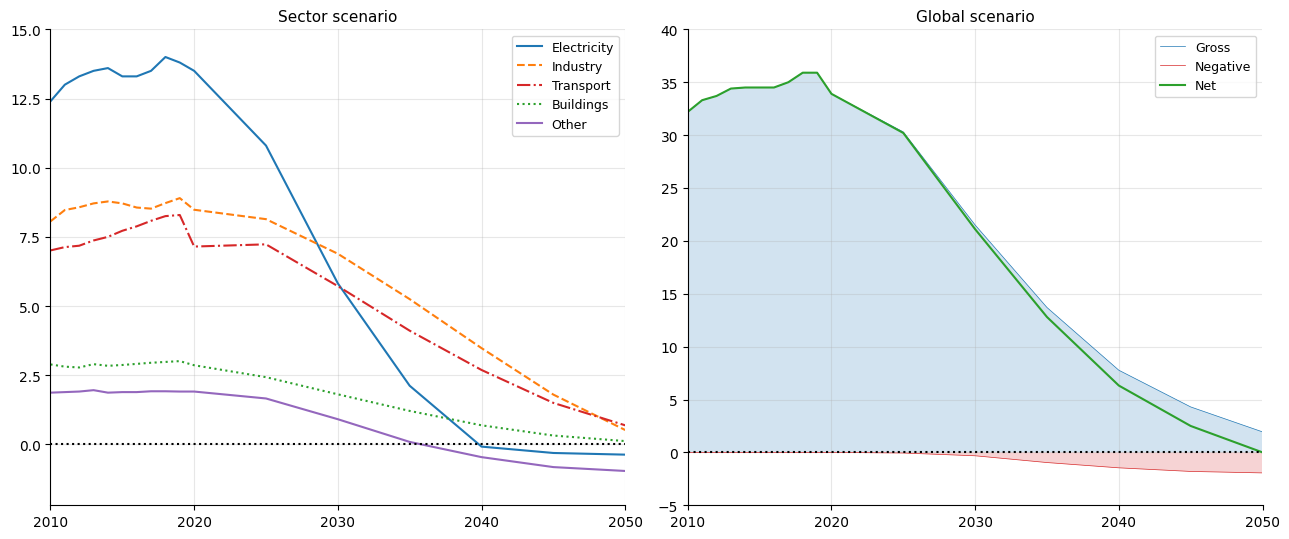

In [3]:
year1 = np.array(
    [
        2010,
        2011,
        2012,
        2013,
        2014,
        2015,
        2016,
        2017,
        2018,
        2019,
        2020,
        2025,
        2030,
        2035,
        2040,
        2045,
        2050,
    ]
)
gross1 = np.array(
    [
        32.20,
        33.30,
        33.70,
        34.40,
        34.50,
        34.50,
        34.50,
        35.00,
        35.90,
        35.90,
        33.90,
        30.30,
        21.50,
        13.70,
        7.77,
        4.30,
        1.94,
    ]
)
negative1 = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -0.06, -0.32, -0.96, -1.46, -1.80, -1.94])
net1 = np.array(
    [
        32.20,
        33.30,
        33.70,
        34.40,
        34.50,
        34.50,
        34.50,
        35.00,
        35.90,
        35.90,
        33.90,
        30.20,
        21.10,
        12.80,
        6.32,
        2.50,
        0.00,
    ]
)

sector_data = {
    "Electricity": [
        12.40,
        13.00,
        13.30,
        13.50,
        13.60,
        13.30,
        13.30,
        13.50,
        14.00,
        13.80,
        13.50,
        10.80,
        5.82,
        2.12,
        -0.08,
        -0.31,
        -0.37,
    ],
    "Buildings": [
        2.89,
        2.81,
        2.78,
        2.90,
        2.84,
        2.87,
        2.91,
        2.95,
        2.98,
        3.01,
        2.86,
        2.43,
        1.81,
        1.21,
        0.69,
        0.32,
        0.12,
    ],
    "Transport": [
        7.01,
        7.13,
        7.18,
        7.37,
        7.50,
        7.72,
        7.88,
        8.08,
        8.25,
        8.29,
        7.15,
        7.23,
        5.72,
        4.11,
        2.69,
        1.50,
        0.69,
    ],
    "Industry": [
        8.06,
        8.47,
        8.57,
        8.71,
        8.78,
        8.71,
        8.56,
        8.52,
        8.72,
        8.90,
        8.48,
        8.14,
        6.89,
        5.25,
        3.48,
        1.80,
        0.52,
    ],
    "Other": [
        1.87,
        1.89,
        1.91,
        1.96,
        1.87,
        1.89,
        1.89,
        1.92,
        1.92,
        1.91,
        1.91,
        1.66,
        0.91,
        0.09,
        -0.46,
        -0.82,
        -0.96,
    ],
}
sector_order = ["Electricity", "Industry", "Transport", "Buildings", "Other"]
sector_styles = [
    ("-", "tab:blue"),
    ("--", "tab:orange"),
    ("-.", "tab:red"),
    (":", "tab:green"),
    ("-", "tab:purple"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
for name, (ls, c) in zip(sector_order, sector_styles):
    ax.plot(year1, sector_data[name], ls, color=c, linewidth=1.5, label=name)
ax.axhline(0, linestyle=":", color="black", linewidth=1.5)
ax.set_title("Sector scenario", fontsize=11)
ax.set_xlim(2010, 2050)
ax.set_xticks(range(2010, 2051, 10))
ax.set_ylim(-2.2, 15)
ax.set_yticks(np.arange(0, 15.1, 2.5))
ax.legend(fontsize=9, loc="upper right")
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(year1, gross1, "-", color="tab:blue", linewidth=0.5)
ax.plot(year1, negative1, "-", color="tab:red", linewidth=0.5)
ax.plot(year1, net1, "-", color="tab:green", linewidth=1.5)
ax.axhline(0, linestyle=":", color="black", linewidth=1.5)
ax.fill_between(year1, gross1, 0, color="tab:blue", alpha=0.20, edgecolor="none")
ax.fill_between(year1, negative1, 0, color="tab:red", alpha=0.20, edgecolor="none")
ax.set_title("Global scenario", fontsize=11)
ax.set_xlim(2010, 2050)
ax.set_xticks(range(2010, 2051, 10))
ax.set_ylim(-5, 36)
ax.set_yticks(range(-5, 41, 5))
ax.legend(["Gross", "Negative", "Net"], fontsize=9, loc="upper right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2. Normalized pathway benchmarks: IEA / NZAOA / CTB / PAB

The global gross-emissions trajectory (IEA scenario), smoothed and
normalized to $100$ at 2020, compared against 3 stylized benchmarks: the
Net-Zero Asset Owner Alliance's (NZAOA) glide path, and the fixed 7%/year
Climate Transition Benchmark (CTB, 30% initial cut) and Paris-Aligned
Benchmark (PAB, 50% initial cut) trajectories.


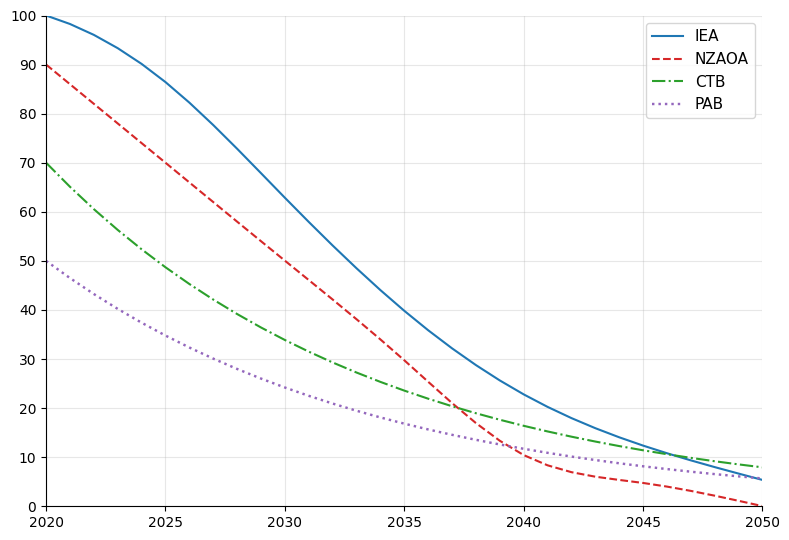

In [4]:
t, y_IEA, y_NZAOA, y_CTB, y_PAB = pathway_benchmarks()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(t, y_IEA, "-", color="tab:blue", linewidth=1.5, label="IEA")
ax.plot(t, y_NZAOA, "--", color="tab:red", linewidth=1.5, label="NZAOA")
ax.plot(t, y_CTB, "-.", color="tab:green", linewidth=1.5, label="CTB")
ax.plot(t, y_PAB, ":", color="tab:purple", linewidth=1.75, label="PAB")
ax.set_xlim(2020, 2050)
ax.set_xticks(range(2020, 2051, 5))
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 10))
ax.legend(fontsize=11, loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Reduction table at selected years

Same 4 benchmark curves as Section 2, expressed as a percentage
*reduction* from the 2020 level ($100-y$) and tabulated at 2020-2029
(annually) then every 5 years to 2050.


In [5]:
selected_t = np.concatenate([np.arange(2020, 2030), np.arange(2030, 2051, 5)])
idx = np.searchsorted(t, selected_t)
table = pd.DataFrame(
    {
        "Year": selected_t,
        "CTB": 100 - y_CTB[idx],
        "PAB": 100 - y_PAB[idx],
        "IEA": 100 - y_IEA[idx],
        "NZAOA": 100 - y_NZAOA[idx],
    }
)
display(table.round(1))

,Year,CTB,PAB,IEA,NZAOA
0,2020,30.0,50.0,0.0,10.0
1,2021,34.9,53.5,1.7,14.0
2,2022,39.5,56.8,3.9,18.0
3,2023,43.7,59.8,6.7,22.0
4,2024,47.6,62.6,9.9,26.0
5,2025,51.3,65.2,13.6,30.0
6,2026,54.7,67.7,17.8,34.0
7,2027,57.9,69.9,22.3,38.0
8,2028,60.8,72.0,27.2,42.0
9,2029,63.6,74.0,32.1,46.0


### 4. Sector-level pathway benchmarks

The same 5 sector trajectories from Section 1, each independently
smoothed and normalized to 100 at 2020 (only the first 4 — Electricity,
Industry, Transport, Buildings — are plotted; "Other" is computed but
not shown). The normalized sector trajectories are kept in memory as
`sector_iea_t`/`sector_iea_y` for reuse later in this chapter.


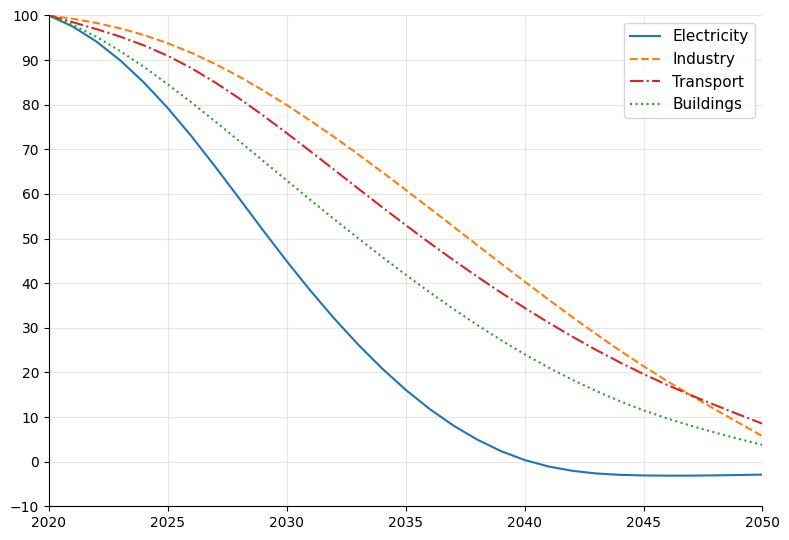

In [6]:
sector_order_full = ["Electricity", "Industry", "Transport", "Buildings", "Other"]
data2 = np.column_stack([sector_data[s] for s in sector_order_full])
idx2020 = np.where(year1 == 2020)[0][0]
data2_norm = 100 * data2 / data2[idx2020, :]

t_sector = np.arange(2020, 2051)
y_sector = np.column_stack([csaps(year1, data2_norm[:, j], t_sector, smooth=0.1) for j in range(5)])
y_sector_IEA = 100 * y_sector / y_sector[0, :]

sector_iea_t, sector_iea_y = t_sector, y_sector_IEA  # kept in memory for reuse in a later notebook

fig, ax = plt.subplots(figsize=(8, 5.5))
styles4 = [("-", "tab:blue"), ("--", "tab:orange"), ("-.", "tab:red"), (":", "tab:green")]
for j, (name, (ls, c)) in enumerate(zip(sector_order_full[:4], styles4)):
    ax.plot(t_sector, y_sector_IEA[:, j], ls, color=c, linewidth=1.5, label=name)
ax.set_xlim(2020, 2050)
ax.set_xticks(range(2020, 2051, 5))
ax.set_ylim(-5, 100)
ax.set_yticks(range(-10, 101, 10))
ax.legend(fontsize=11, loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Advanced vs. developing economies: emissions and intensity

Carbon emissions (CE) and carbon intensity (CI) trajectories for advanced
vs. developing economies, 2010-2050, each smoothed and normalized to 100
at 2020, on a finer 0.1-year grid.


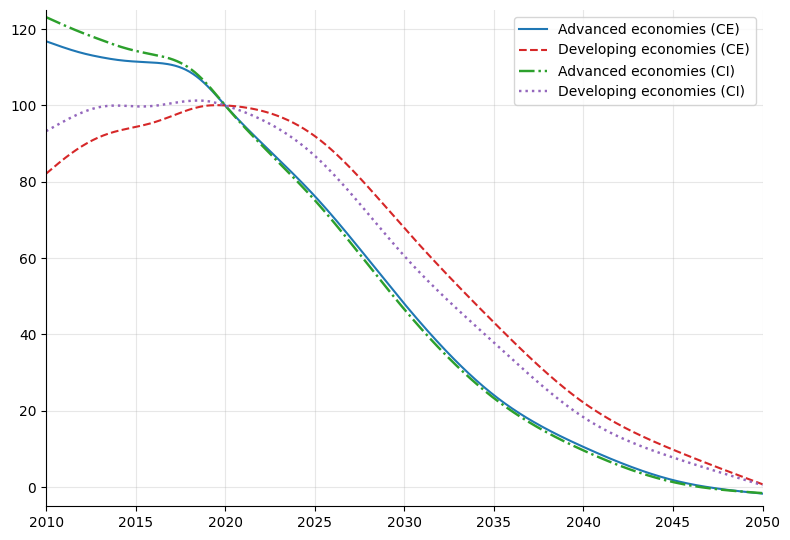

In [7]:
year8 = np.array(
    [
        2010,
        2011,
        2012,
        2013,
        2014,
        2015,
        2016,
        2017,
        2018,
        2019,
        2020,
        2025,
        2030,
        2035,
        2040,
        2045,
        2050,
    ]
)
ce_adv = np.array(
    [
        13423,
        13193,
        12949,
        12991,
        12759,
        12721,
        12663,
        12664,
        12746,
        12312,
        11057,
        8793,
        5494,
        2737,
        1232,
        196,
        -183,
    ]
)
ce_dev = np.array(
    [
        18810,
        20090,
        20757,
        21434,
        21788,
        21738,
        21857,
        22348,
        23122,
        23614,
        22846,
        21442,
        15653,
        10048,
        5084,
        2303,
        183,
    ]
)
ci_adv = np.array(
    [10.1, 9.9, 9.7, 9.7, 9.4, 9.3, 9.2, 9.2, 9.2, 8.8, 7.91, 6.2, 3.8, 1.9, 0.8, 0.1, -0.12]
)
ci_dev = np.array(
    [3.4, 3.5, 3.6, 3.7, 3.7, 3.6, 3.6, 3.7, 3.7, 3.8, 3.60, 3.2, 2.2, 1.4, 0.66, 0.29, 0.02]
)
data8 = np.column_stack([ce_adv, ce_dev, ci_adv, ci_dev])
idx2020_8 = np.where(year8 == 2020)[0][0]
data8_norm = 100 * data8 / data8[idx2020_8, :]

t8 = np.arange(2010, 2050.01, 0.1)
y8 = np.column_stack([csaps(year8, data8_norm[:, j], t8, smooth=0.4) for j in range(4)])
idx2020_t8 = np.argmin(np.abs(t8 - 2020))
y8 = 100 * y8 / y8[idx2020_t8, :]

fig, ax = plt.subplots(figsize=(8, 5.5))
labels8 = [
    "Advanced economies (CE)",
    "Developing economies (CE)",
    "Advanced economies (CI)",
    "Developing economies (CI)",
]
styles8 = [("-", "tab:blue"), ("--", "tab:red"), ("-.", "tab:green"), (":", "tab:purple")]
for j, (label, (ls, c)) in enumerate(zip(labels8, styles8)):
    ax.plot(t8, y8[:, j], ls, color=c, linewidth=1.5 if j < 2 else 1.75, label=label)
ax.set_xlim(2010, 2050)
ax.set_xticks(range(2010, 2051, 5))
ax.set_ylim(-5, 125)
ax.set_yticks(range(0, 131, 20))
ax.legend(fontsize=10, loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<a id="part-11g"></a>

## Part 2 — 11g: Net-zero carbon budget: compounding reduction worked examples

Three worked examples of how a compounding annual emissions-reduction rate
translates into a cumulative "carbon budget" consumed over a horizon. All
three rely on `carbon_budget_compound_reduction(t0,t,Delta_R,R_minus,
CE_t0[,g_Y])`, defined below and validated by cross-checking its sign and
scale (see the derivation cell) against a bisection precondition used in
the third example.


**Deriving `carbon_budget_compound_reduction`.** The underlying model:
emissions at year $s\in[t_0,t]$ decline from a baseline $CE_{t_0}$ by an
immediate one-time cut $R_{-}$ at $t_0$, then compound at rate $\Delta R$
per year (optionally net of a GDP growth rate $g_Y$ that offsets the
reduction):
$$CE(s) = CE_{t_0}\,(1-R_{-})\,\big[(1-\Delta R)(1+g_Y)\big]^{s-t_0}$$
and the "carbon budget" is the cumulative sum
$CB=\sum_{s=t_0}^{t}CE(s)$. This is the same compounding-decline model
used for the `CTB`/`PAB` benchmark curves in `11f`
($100\times(1-0.07)^{t-t_0}(1-0.30)$), which is where the
$(1-\Delta R)$/$(1-R_-)$ roles were first confirmed. The function returns
two identical values (`CB1`, `CB2`) since only one is ever needed at each
call site below. **Validation**: the third example searches for
$\Delta R\in[0,0.50]$ hitting a target cumulative budget of 750
(GtCO$_2$) over 2020-2030 from a $CE_{t_0}=100$ baseline, guarded by
`(CB_theta(theta_min)<0) and (CB_theta(theta_max)>0)` — i.e. it expects
the *unreduced* cumulative budget to exceed 750 and the *maximally
reduced* one to fall short. Plugging the formula in: $\Delta R=0$ gives
$CB=1100$ (exceeds 750 ✓) and $\Delta R=0.50$ gives $CB\approx199.9$
(falls short ✓) — confirming the sign pattern the bisection search
relies on.


In [8]:
def carbon_budget_compound_reduction(t0, t, Delta_R, R_minus, CE_t0, g_Y=0.0):
    CB = _qtb_cbcr(t0, t, Delta_R, R_minus, CE_t0, g_y=g_Y, discrete=True)
    return CB, CB  # CB1, CB2 -- see markdown above on why both are identical here


def estimate_delta_R(t0, t, theta_min, theta_max, R_minus, g_Y, CE_t0, CB_target):
    # Bisection search for the compounding reduction rate hitting a
    # target cumulative carbon budget.
    def CB_theta(theta):
        return CB_target - carbon_budget_compound_reduction(t0, t, theta, R_minus, CE_t0, g_Y)[0]

    if CB_theta(theta_min) < 0 and CB_theta(theta_max) > 0:
        return brentq(CB_theta, theta_min, theta_max)
    return np.nan

### 1. Cumulative carbon budget under compounding reduction

A $6\times6$ grid: annual reduction rate $\Delta R\in\{5\%,\dots,10\%\}$
(rows) against an initial one-time cut $R_{-}\in\{0\%,10\%,20\%,30\%,50\%,
75\%\}$ (columns), cumulative emissions 2020-2050 from a $36$
GtCO$_2$/year baseline (roughly today's global CO$_2$ emissions rate).


In [9]:
t0, t = 2020, 2050
R_minus_grid = np.array([0.00, 0.10, 0.20, 0.30, 0.50, 0.75])
Delta_R_grid = np.array([0.05, 0.06, 0.07, 0.08, 0.09, 0.10])
CE_t0 = 36

CB2 = np.zeros((len(Delta_R_grid), len(R_minus_grid)))
for i, dR in enumerate(Delta_R_grid):
    for j, Rm in enumerate(R_minus_grid):
        _, CB2[i, j] = carbon_budget_compound_reduction(t0, t, dR, Rm, CE_t0)

table1 = pd.DataFrame(
    CB2.round(0),
    index=[f"{100 * d:.0f}%" for d in Delta_R_grid],
    columns=[f"{100 * r:.0f}%" for r in R_minus_grid],
)
table1.index.name = "Delta R \\ R-"
display(table1)

,0%,10%,20%,30%,50%,75%
Delta R \ R-,,,,,,
5%,573.0,516.0,459.0,401.0,287.0,143.0
6%,512.0,461.0,409.0,358.0,256.0,128.0
7%,460.0,414.0,368.0,322.0,230.0,115.0
8%,416.0,374.0,333.0,291.0,208.0,104.0
9%,379.0,341.0,303.0,265.0,189.0,95.0
10%,346.0,312.0,277.0,242.0,173.0,87.0


### 2. Same grid, now with GDP growth offsetting the reduction

The same $\Delta R\times R_{-}$ grid repeated for 4 GDP growth
assumptions $g_Y\in\{1\%,3\%,5\%,10\%\}$ — higher growth erodes more of
the compounding reduction each year, so the cumulative budget rises with
$g_Y$ at every grid point.


In [10]:
g_Y_values = [0.01, 0.03, 0.05, 0.10]
all_CB = {}
for g_Y in g_Y_values:
    CB2_g = np.zeros((len(Delta_R_grid), len(R_minus_grid)))
    for i, dR in enumerate(Delta_R_grid):
        for j, Rm in enumerate(R_minus_grid):
            _, CB2_g[i, j] = carbon_budget_compound_reduction(t0, t, dR, Rm, CE_t0, g_Y)
    all_CB[g_Y] = CB2_g
    print(f"g_Y = {int(100 * g_Y)}%")
    display(
        pd.DataFrame(
            CB2_g.round(0),
            index=[f"{100 * d:.0f}%" for d in Delta_R_grid],
            columns=[f"{100 * r:.0f}%" for r in R_minus_grid],
        )
    )

combined = np.block([[all_CB[0.01], all_CB[0.03]], [all_CB[0.05], all_CB[0.10]]])
print("Combined 12x12 table (top-left=1%, top-right=3%, bottom-left=5%, bottom-right=10%)")
display(pd.DataFrame(combined.round(0)))

g_Y = 1%


,0%,10%,20%,30%,50%,75%
5%,642.0,578.0,514.0,450.0,321.0,161.0
6%,569.0,512.0,455.0,398.0,285.0,142.0
7%,508.0,457.0,406.0,356.0,254.0,127.0
8%,456.0,411.0,365.0,319.0,228.0,114.0
9%,412.0,371.0,330.0,289.0,206.0,103.0
10%,375.0,338.0,300.0,263.0,188.0,94.0


g_Y = 3%


,0%,10%,20%,30%,50%,75%
5%,821.0,739.0,657.0,575.0,410.0,205.0
6%,716.0,645.0,573.0,501.0,358.0,179.0
7%,630.0,567.0,504.0,441.0,315.0,157.0
8%,557.0,502.0,446.0,390.0,279.0,139.0
9%,497.0,447.0,398.0,348.0,249.0,124.0
10%,446.0,402.0,357.0,312.0,223.0,112.0


g_Y = 5%


,0%,10%,20%,30%,50%,75%
5%,1075.0,968.0,860.0,753.0,538.0,269.0
6%,923.0,831.0,739.0,646.0,462.0,231.0
7%,799.0,719.0,639.0,559.0,399.0,200.0
8%,696.0,627.0,557.0,488.0,348.0,174.0
9%,612.0,551.0,489.0,428.0,306.0,153.0
10%,541.0,487.0,433.0,379.0,271.0,135.0


g_Y = 10%


,0%,10%,20%,30%,50%,75%
5%,2331.0,2098.0,1865.0,1632.0,1166.0,583.0
6%,1926.0,1734.0,1541.0,1348.0,963.0,482.0
7%,1602.0,1442.0,1282.0,1122.0,801.0,401.0
8%,1342.0,1208.0,1074.0,940.0,671.0,336.0
9%,1133.0,1020.0,906.0,793.0,566.0,283.0
10%,964.0,867.0,771.0,675.0,482.0,241.0


Combined 12x12 table (top-left=1%, top-right=3%, bottom-left=5%, bottom-right=10%)


,0,1,2,3,4,5,6,7,8,9,10,11
0,642.0,578.0,514.0,450.0,321.0,161.0,821.0,739.0,657.0,575.0,410.0,205.0
1,569.0,512.0,455.0,398.0,285.0,142.0,716.0,645.0,573.0,501.0,358.0,179.0
2,508.0,457.0,406.0,356.0,254.0,127.0,630.0,567.0,504.0,441.0,315.0,157.0
3,456.0,411.0,365.0,319.0,228.0,114.0,557.0,502.0,446.0,390.0,279.0,139.0
4,412.0,371.0,330.0,289.0,206.0,103.0,497.0,447.0,398.0,348.0,249.0,124.0
5,375.0,338.0,300.0,263.0,188.0,94.0,446.0,402.0,357.0,312.0,223.0,112.0
6,1075.0,968.0,860.0,753.0,538.0,269.0,2331.0,2098.0,1865.0,1632.0,1166.0,583.0
7,923.0,831.0,739.0,646.0,462.0,231.0,1926.0,1734.0,1541.0,1348.0,963.0,482.0
8,799.0,719.0,639.0,559.0,399.0,200.0,1602.0,1442.0,1282.0,1122.0,801.0,401.0
9,696.0,627.0,557.0,488.0,348.0,174.0,1342.0,1208.0,1074.0,940.0,671.0,336.0


### 3. Solving for the reduction rate hitting a target budget

A $100$ GtCO$_2$/year baseline (2020) targeting a cumulative budget of
$750$ GtCO$_2$ over 2020-2030: `estimate_delta_R` bisects for the
compounding rate $\Delta R$ that exactly hits the target, first with no
growth offset, then adjusted for $g_Y=3\%$ via the identity
$\theta'=1-\frac{1-\theta}{1+g_Y}$ (the growth-adjusted rate that
reproduces the same *net* decline once growth is added back — i.e.
$(1-\theta')(1+g_Y)=(1-\theta)$).


In [11]:
R_minus3, CE_t0_3, CB_target = 0.00, 100, 750
t0_3, t_3 = 2020, 2050

g_Y = 0.00
theta = estimate_delta_R(2020, 2030, 0, 0.50, R_minus3, g_Y, CE_t0_3, CB_target)
print(f"g_Y=0%:  Delta_R solving CB(2020-2030)=750 -> theta = {theta:.4f}")

g_Y = 0.03
theta_adj = 1 - (1 - theta) / (1 + g_Y)
print(f"g_Y=3%:  growth-adjusted equivalent theta = {theta_adj:.4f}")

CB_min, _ = carbon_budget_compound_reduction(t0_3, t_3, 0.00, R_minus3, CE_t0_3, g_Y)
CB_max, _ = carbon_budget_compound_reduction(t0_3, t_3, 0.20, R_minus3, CE_t0_3, g_Y)
print(
    f"2020-2050 cumulative budget bracket at g_Y=3%: [Delta_R=0% -> {CB_min:.1f}, Delta_R=20% -> {CB_max:.1f}]"
)

theta2 = estimate_delta_R(2020, 2030, 0, 0.50, R_minus3, g_Y, CE_t0_3, CB_target)
print(f"g_Y=3%:  Delta_R solving CB(2020-2030)=750 directly -> theta = {theta2:.4f}")

g_Y=0%:  Delta_R solving CB(2020-2030)=750 -> theta = 0.0801
g_Y=3%:  growth-adjusted equivalent theta = 0.1069
2020-2050 cumulative budget bracket at g_Y=3%: [Delta_R=0% -> 5000.3, Delta_R=20% -> 566.8]
g_Y=3%:  Delta_R solving CB(2020-2030)=750 directly -> theta = 0.1069
